In [1]:
%pip install -U langchain-core langchain-community langchain-text-splitters langchain-ollama langchain-chroma chromadb pandas matplotlib

  Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pillow-12.3.0-cp311-cp311-win_amd64.whl.metadata (9.3 kB)
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.9 MB 2.8 MB/s eta 0:00:04
   ----- ---------------------------------- 1.3/9.9 MB 3.5 MB/s eta 0:00:03
   --------- ------------------------------ 2.4/9.9 MB 4.3 MB/s eta 0:00:02
   ------------- -------------------------- 3.4/9.9 MB 4.3 MB/s eta 0:00:02
   --------------- ------------------------ 3.9/9.9 MB 4.3 MB/s eta 0:00:02
   ------------------ --------------------- 4.5/9.9 MB 3.7 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.9 MB 3.3 MB/s eta 0:00:02
   ---------------------- ----------------- 5.5/9.9 MB 3.4 MB/s eta 0:00:02
   ------------------------- -------------- 6.3/9.9 MB 3.4 MB/s eta 0:00:02
   ----------------------------- --

# Question 2: Comparative RAG System Using Three Retrieval Configurations

In [1]:
from pathlib import Path

downloads = Path.home() / "Downloads"

for item in downloads.iterdir():
    print(item.name)

.ipynb_checkpoints
1776311194-1776165716-1730262489-1729507042-DIY Project ppt template - Copy.pptx
1776311302-P3-Car Market Trends Analysis with Car Dekho Data.csv
22_8_2026, 11_57_52 am - Screen - Video Project.webm
3456146.3456163.pdf
5.pdf
50_Aptitude_Shortcuts.pdf
5th SEM Industrial Certificate.pdf
5th SEM Industrial score card.pdf
5th sem marks sheet.pdf
6.pdf
6ab674645103d_emails_comms_amazon_ml_challenge_2026.pdf
6th SEM marks sheet.pdf
9ddc84d2-871e-4423-a586-a2574a2c6d43_report.json
About Eurofins.pdf
AI PROBLEM STATEMENTS 3.pdf
AI_Notes.txt
Anaconda3-2025.12-2-Windows-x86_64.exe
Annexure III - Project Diary.pdf
Applied Computational Intelligence and Soft Computing - 2024 - Ahmed - Student Performance Prediction Using Machine.pdf
arr.txt
Assignment Q.1.ipynb
Assignment questions.pdf
business_study_retail_ecommerce.docx
Car_Market_Trends_Analysis.ipynb
certificate-Spandana basava kulal.pdf
Chalini_M_Resume_v2 (1).pdf
ChatGPT Image Sep 3, 2026, 03_50_44 PM.png
ChatGPT Image Sep

In [2]:
from pathlib import Path

DOCS_DIR = None

for path in (Path.home() / "Downloads").rglob("documents"):
    if path.is_dir() and len(list(path.glob("*.txt"))) >= 15:
        DOCS_DIR = path
        break

if DOCS_DIR:
    print("Found folder:", DOCS_DIR)
    print("TXT files:", len(list(DOCS_DIR.glob("*.txt"))))
else:
    print("Could not find the folder. Check the output from Step 1.")

Found folder: C:\Users\HP\Downloads\comparative_rag_project\comparative_rag_project\documents
TXT files: 17


In [4]:
from langchain_community.document_loaders import TextLoader

documents = []

for file_path in sorted(DOCS_DIR.glob("*.txt")):
    loaded = TextLoader(
        str(file_path),
        encoding="utf-8"
    ).load()

    for doc in loaded:
        doc.metadata["source"] = file_path.name
        documents.append(doc)

print("Total documents:", len(documents))
print("Unique files:", len(set(d.metadata["source"] for d in documents)))

Total documents: 17
Unique files: 17


C:\Users\HP\AppData\Local\Temp\ipykernel_24608\4157572854.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import TextLoader


In [5]:
# Define the three chunking configurations
from langchain_text_splitters import RecursiveCharacterTextSplitter

configurations = {
    "RAG_A": {"chunk_size": 300, "chunk_overlap": 50},
    "RAG_B": {"chunk_size": 600, "chunk_overlap": 100},
    "RAG_C": {"chunk_size": 1000, "chunk_overlap": 200}
}

split_documents = {}

for name, config in configurations.items():
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=config["chunk_size"],
        chunk_overlap=config["chunk_overlap"],
        separators=["\n\n", "\n", ". ", " ", ""]
    )

    chunks = splitter.split_documents(documents)
    split_documents[name] = chunks

    print(
        name,
        "| Chunk size:", config["chunk_size"],
        "| Overlap:", config["chunk_overlap"],
        "| Total chunks:", len(chunks)
    )

RAG_A | Chunk size: 300 | Overlap: 50 | Total chunks: 52
RAG_B | Chunk size: 600 | Overlap: 100 | Total chunks: 17
RAG_C | Chunk size: 1000 | Overlap: 200 | Total chunks: 17


In [6]:
# Create three separate ChromaDB collections
from langchain_ollama import OllamaEmbeddings
from langchain_chroma import Chroma
from pathlib import Path
import shutil

embeddings = OllamaEmbeddings(model="nomic-embed-text")

DB_DIR = Path("comparative_chroma_db")
DB_DIR.mkdir(exist_ok=True)

vectorstores = {}

for name, chunks in split_documents.items():
    collection_name = name.lower()

    store_path = DB_DIR / collection_name

    if store_path.exists():
        shutil.rmtree(store_path)

    vectorstores[name] = Chroma.from_documents(
        documents=chunks,
        embedding=embeddings,
        persist_directory=str(store_path),
        collection_name=collection_name
    )

    print(
        name,
        "| Stored chunks:", len(chunks),
        "| Collection:", collection_name
    )

print("\nAll three ChromaDB collections created successfully!")

RAG_A | Stored chunks: 52 | Collection: rag_a
RAG_B | Stored chunks: 17 | Collection: rag_b
RAG_C | Stored chunks: 17 | Collection: rag_c

All three ChromaDB collections created successfully!


In [7]:
# Define the ten evaluation questions
questions = [
    "What is the difference between supervised and unsupervised learning?",
    "How does backpropagation help train a neural network?",
    "What are transformers and how does self-attention work?",
    "What is retrieval-augmented generation and what are its main steps?",
    "Why are vector embeddings useful, and what do similarity scores not guarantee?",
    "Which classification metrics are useful for imbalanced datasets?",
    "What is data leakage and how can it be avoided?",
    "Name methods that can reduce overfitting.",
    "What information can metadata store in a vector database?",
    "What should a responsible data science workflow consider beyond accuracy?"
]

print("Total evaluation questions:", len(questions))

Total evaluation questions: 10


In [8]:
# Compare retrieval time for all configurations
import time
import pandas as pd

retrieval_results = []

for config_name, vectorstore in vectorstores.items():
    for k in [2, 4, 6]:
        for question_id, question in enumerate(questions, start=1):

            start_time = time.perf_counter()

            retrieved_docs = vectorstore.similarity_search(
                question,
                k=k
            )

            elapsed_time = time.perf_counter() - start_time

            retrieval_results.append({
                "Configuration": config_name,
                "k": k,
                "Question_ID": question_id,
                "Retrieval_Time_Seconds": elapsed_time,
                "Retrieved_Chunks": len(retrieved_docs)
            })

retrieval_df = pd.DataFrame(retrieval_results)

print("Total retrieval experiments:", len(retrieval_df))
display(retrieval_df.head(10))

Total retrieval experiments: 90


,Configuration,k,Question_ID,Retrieval_Time_Seconds,Retrieved_Chunks
0,RAG_A,2,1,0.183364,2
1,RAG_A,2,2,0.064034,2
2,RAG_A,2,3,0.058997,2
3,RAG_A,2,4,0.052103,2
4,RAG_A,2,5,0.052390,2
5,RAG_A,2,6,0.047980,2
6,RAG_A,2,7,0.047428,2
7,RAG_A,2,8,0.042338,2
8,RAG_A,2,9,0.043827,2
9,RAG_A,2,10,0.047250,2


In [9]:
# Generate the retrieval-time comparison table
retrieval_summary = (
    retrieval_df
    .groupby(["Configuration", "k"], as_index=False)
    .agg(
        Mean_Retrieval_Time=("Retrieval_Time_Seconds", "mean"),
        Mean_Chunks_Retrieved=("Retrieved_Chunks", "mean")
    )
)

display(retrieval_summary.round(5))

,Configuration,k,Mean_Retrieval_Time,Mean_Chunks_Retrieved
0,RAG_A,2,0.06397,2.0
1,RAG_A,4,0.04647,4.0
2,RAG_A,6,0.04786,6.0
3,RAG_B,2,0.04722,2.0
4,RAG_B,4,0.04637,4.0
5,RAG_B,6,0.04562,6.0
6,RAG_C,2,0.04684,2.0
7,RAG_C,4,0.04535,4.0
8,RAG_C,6,0.04629,6.0


In [10]:

from langchain_ollama import ChatOllama
import time
import pandas as pd

llm = ChatOllama(
    model="llama3.2",
    temperature=0
)

# Pilot: 3 questions × 3 configurations × 3 values of k = 27 runs
pilot_questions = questions[:3]

answer_results = []

total = len(vectorstores) * len([2, 4, 6]) * len(pilot_questions)
done = 0

for config_name, vectorstore in vectorstores.items():
    for k in [2, 4, 6]:
        for question_id, question in enumerate(pilot_questions, start=1):

            retrieved_docs = vectorstore.similarity_search(
                question, k=k
            )

            context = "\n\n".join(
                f"[S{i}] {doc.metadata.get('source', 'Unknown')}\n"
                f"{doc.page_content}"
                for i, doc in enumerate(retrieved_docs, start=1)
            )

            prompt = f"""
Answer using only the supplied evidence.
Cite supporting sources using labels such as [S1].
If evidence is insufficient, say so.
Do not invent facts.

Question:
{question}

Evidence:
{context}

Answer:
"""

            start = time.perf_counter()
            response = llm.invoke(prompt)
            generation_time = time.perf_counter() - start

            answer_results.append({
                "Configuration": config_name,
                "k": k,
                "Question_ID": question_id,
                "Question": question,
                "Answer": response.content,
                "Sources": "; ".join(sorted(set(
                    doc.metadata.get("source", "Unknown")
                    for doc in retrieved_docs
                ))),
                "Evidence": context,
                "Generation_Time_Seconds": generation_time,
                "Answer_Relevance_1_to_5": None,
                "Answer_Completeness_1_to_5": None
            })

            done += 1
            print(f"Completed {done}/{total}")

answer_df = pd.DataFrame(answer_results)

print("\nTotal generated answers:", len(answer_df))
display(answer_df.head(3))


Completed 1/27
Completed 2/27
Completed 3/27
Completed 4/27
Completed 5/27
Completed 6/27
Completed 7/27
Completed 8/27
Completed 9/27
Completed 10/27
Completed 11/27
Completed 12/27
Completed 13/27
Completed 14/27
Completed 15/27
Completed 16/27
Completed 17/27
Completed 18/27
Completed 19/27
Completed 20/27
Completed 21/27
Completed 22/27
Completed 23/27
Completed 24/27
Completed 25/27
Completed 26/27
Completed 27/27

Total generated answers: 27


,Configuration,k,Question_ID,Question,Answer,Sources,Evidence,Generation_Time_Seconds,Answer_Relevance_1_to_5,Answer_Completeness_1_to_5
0,RAG_A,2,1,What is the difference between supervised and ...,"According to the evidence, the difference betw...",01_machine_learning.txt; 03_unsupervised_learn...,[S1] 03_unsupervised_learning.txt\nUnsupervise...,19.309268,None,None
1,RAG_A,2,2,How does backpropagation help train a neural n...,Backpropagation helps train a neural network b...,05_neural_networks.txt,[S1] 05_neural_networks.txt\nNeural Networks a...,6.266810,None,None
2,RAG_A,2,3,What are transformers and how does self-attent...,Transformers use attention mechanisms to model...,07_transformers.txt,[S1] 07_transformers.txt\nTransformers use att...,10.806012,None,None


In [11]:
from pathlib import Path

RESULTS_DIR = Path("comparative_rag_results")
RESULTS_DIR.mkdir(exist_ok=True)

answer_df.to_csv(
    RESULTS_DIR / "answer_results.csv",
    index=False
)

retrieval_df.to_csv(
    RESULTS_DIR / "retrieval_times.csv",
    index=False
)

print("Answers saved:", len(answer_df))
print("Retrieval measurements saved:", len(retrieval_df))
print("Results folder:", RESULTS_DIR.resolve())

Answers saved: 27
Retrieval measurements saved: 90
Results folder: C:\Users\HP\comparative_rag_results


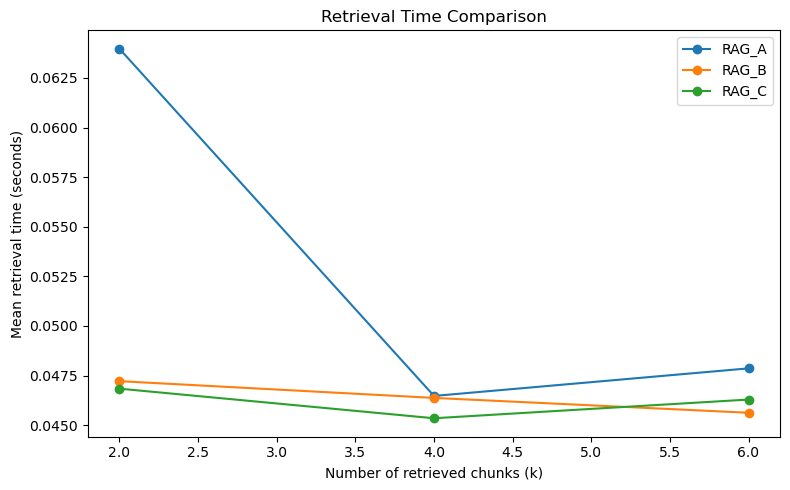

In [12]:
# Create the retrieval-time graph
import matplotlib.pyplot as plt

retrieval_summary = (
    retrieval_df
    .groupby(["Configuration", "k"])["Retrieval_Time_Seconds"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8, 5))

for config in ["RAG_A", "RAG_B", "RAG_C"]:
    data = retrieval_summary[
        retrieval_summary["Configuration"] == config
    ]
    plt.plot(
        data["k"],
        data["Retrieval_Time_Seconds"],
        marker="o",
        label=config
    )

plt.xlabel("Number of retrieved chunks (k)")
plt.ylabel("Mean retrieval time (seconds)")
plt.title("Retrieval Time Comparison")
plt.legend()
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "retrieval_time_comparison.png",
    dpi=150
)
plt.show()

In [13]:
# Create the answer-quality comparison
scoring_df = answer_df[
    [
        "Configuration",
        "k",
        "Question_ID",
        "Question",
        "Answer",
        "Evidence",
        "Answer_Relevance_1_to_5",
        "Answer_Completeness_1_to_5"
    ]
].copy()

scoring_df.to_csv(
    RESULTS_DIR / "answer_results_scored.csv",
    index=False
)

display(scoring_df.head())

,Configuration,k,Question_ID,Question,Answer,Evidence,Answer_Relevance_1_to_5,Answer_Completeness_1_to_5
0,RAG_A,2,1,What is the difference between supervised and ...,"According to the evidence, the difference betw...",[S1] 03_unsupervised_learning.txt\nUnsupervise...,None,None
1,RAG_A,2,2,How does backpropagation help train a neural n...,Backpropagation helps train a neural network b...,[S1] 05_neural_networks.txt\nNeural Networks a...,None,None
2,RAG_A,2,3,What are transformers and how does self-attent...,Transformers use attention mechanisms to model...,[S1] 07_transformers.txt\nTransformers use att...,None,None
3,RAG_A,4,1,What is the difference between supervised and ...,"According to the evidence, the main difference...",[S1] 03_unsupervised_learning.txt\nUnsupervise...,None,None
4,RAG_A,4,2,How does backpropagation help train a neural n...,Backpropagation helps train a neural network b...,[S1] 05_neural_networks.txt\nNeural Networks a...,None,None


In [16]:

import json
import re
import time
import pandas as pd

scored = answer_df.copy()

def evaluate_answer(question, answer, evidence):
    prompt = f"""
Evaluate this RAG answer using the question and retrieved evidence.

Score both criteria from 1 to 5:
Relevance:
1 = unrelated or unsupported
3 = partially answers the question
5 = directly answers the question and is evidence-grounded

Completeness:
1 = misses most important points
3 = covers some important points
5 = covers all important points supported by the evidence

Do not reward unsupported claims. Use the evidence, not outside knowledge.
Return JSON only:
{{"relevance": 1, "completeness": 1}}

Question: {question}
Answer: {answer}
Evidence: {evidence}
"""

    response = llm.invoke(prompt).content
    match = re.search(r"\{.*\}", response, re.S)

    if not match:
        return None, None

    try:
        result = json.loads(match.group())
        relevance = int(result["relevance"])
        completeness = int(result["completeness"])

        if relevance not in range(1, 6) or completeness not in range(1, 6):
            return None, None

        return relevance, completeness
    except (ValueError, KeyError, json.JSONDecodeError):
        return None, None

for i, row in scored.iterrows():
    relevance, completeness = evaluate_answer(
        row["Question"],
        row["Answer"],
        row["Evidence"]
    )

    scored.at[i, "Answer_Relevance_1_to_5"] = relevance
    scored.at[i, "Answer_Completeness_1_to_5"] = completeness

    print(f"Evaluated {i + 1}/{len(scored)}")

    # Save progress so partial results are not lost.
    scored.to_csv(
        RESULTS_DIR / "answer_results_scored.csv",
        index=False
    )

print("Scoring finished.")


Evaluated 1/27
Evaluated 2/27
Evaluated 3/27
Evaluated 4/27
Evaluated 5/27
Evaluated 6/27
Evaluated 7/27
Evaluated 8/27
Evaluated 9/27
Evaluated 10/27
Evaluated 11/27
Evaluated 12/27
Evaluated 13/27
Evaluated 14/27
Evaluated 15/27
Evaluated 16/27
Evaluated 17/27
Evaluated 18/27
Evaluated 19/27
Evaluated 20/27
Evaluated 21/27
Evaluated 22/27
Evaluated 23/27
Evaluated 24/27
Evaluated 25/27
Evaluated 26/27
Evaluated 27/27
Scoring finished.


In [17]:
print("Missing relevance scores:",
      scored["Answer_Relevance_1_to_5"].isna().sum())

print("Missing completeness scores:",
      scored["Answer_Completeness_1_to_5"].isna().sum())

Missing relevance scores: 0
Missing completeness scores: 0


,Configuration,k,Mean_Relevance,Mean_Completeness
0,RAG_A,2,3.00,3.00
1,RAG_A,4,3.67,3.33
2,RAG_A,6,4.33,3.67
3,RAG_B,2,4.33,4.33
4,RAG_B,4,3.67,3.67
5,RAG_B,6,3.67,3.67
6,RAG_C,2,4.33,3.67
7,RAG_C,4,3.67,3.67
8,RAG_C,6,3.67,3.67


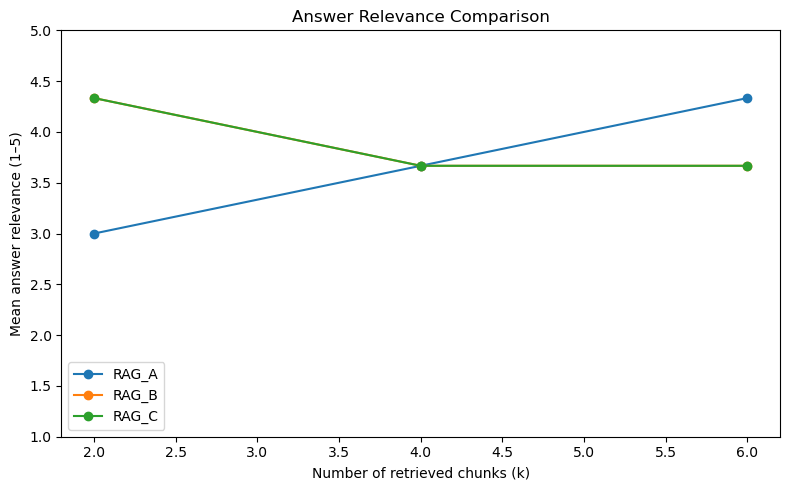

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

scored = pd.read_csv(
    RESULTS_DIR / "answer_results_scored.csv"
)

quality_summary = (
    scored
    .groupby(["Configuration", "k"], as_index=False)
    .agg(
        Mean_Relevance=("Answer_Relevance_1_to_5", "mean"),
        Mean_Completeness=("Answer_Completeness_1_to_5", "mean")
    )
)

display(quality_summary.round(2))

plt.figure(figsize=(8, 5))

for config in ["RAG_A", "RAG_B", "RAG_C"]:
    subset = quality_summary[
        quality_summary["Configuration"] == config
    ]
    plt.plot(
        subset["k"],
        subset["Mean_Relevance"],
        marker="o",
        label=config
    )

plt.xlabel("Number of retrieved chunks (k)")
plt.ylabel("Mean answer relevance (1–5)")
plt.title("Answer Relevance Comparison")
plt.ylim(1, 5)
plt.legend()
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "answer_relevance_comparison.png",
    dpi=150
)
plt.show()

In [19]:
# Check the actual scores
display(
    quality_summary[
        [
            "Configuration",
            "k",
            "Mean_Relevance",
            "Mean_Completeness"
        ]
    ].round(2)
)

,Configuration,k,Mean_Relevance,Mean_Completeness
0,RAG_A,2,3.00,3.00
1,RAG_A,4,3.67,3.33
2,RAG_A,6,4.33,3.67
3,RAG_B,2,4.33,4.33
4,RAG_B,4,3.67,3.67
5,RAG_B,6,3.67,3.67
6,RAG_C,2,4.33,3.67
7,RAG_C,4,3.67,3.67
8,RAG_C,6,3.67,3.67


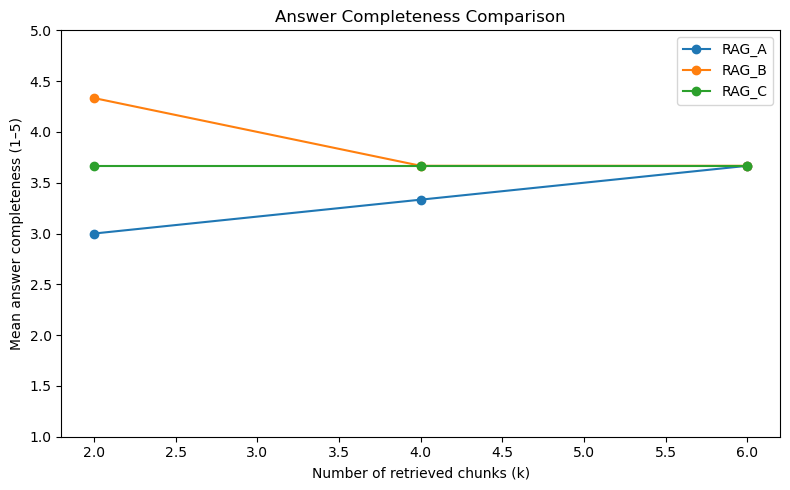

In [20]:
# Create the completeness graph
plt.figure(figsize=(8, 5))

for config in ["RAG_A", "RAG_B", "RAG_C"]:
    subset = quality_summary[
        quality_summary["Configuration"] == config
    ]

    plt.plot(
        subset["k"],
        subset["Mean_Completeness"],
        marker="o",
        label=config
    )

plt.xlabel("Number of retrieved chunks (k)")
plt.ylabel("Mean answer completeness (1–5)")
plt.title("Answer Completeness Comparison")
plt.ylim(1, 5)
plt.legend()
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "answer_completeness_comparison.png",
    dpi=150
)
plt.show()

In [21]:
# Generate the comparison table
final_summary = (
    scored
    .groupby(["Configuration", "k"], as_index=False)
    .agg(
        Mean_Relevance=("Answer_Relevance_1_to_5", "mean"),
        Mean_Completeness=("Answer_Completeness_1_to_5", "mean")
    )
)

final_summary = final_summary.merge(
    retrieval_summary,
    on=["Configuration", "k"],
    how="left"
)

display(final_summary.round(4))

final_summary.to_csv(
    RESULTS_DIR / "final_comparison_table.csv",
    index=False
)

print("Comparison table saved successfully.")

,Configuration,k,Mean_Relevance,Mean_Completeness,Retrieval_Time_Seconds
0,RAG_A,2,3.0000,3.0000,0.0640
1,RAG_A,4,3.6667,3.3333,0.0465
2,RAG_A,6,4.3333,3.6667,0.0479
3,RAG_B,2,4.3333,4.3333,0.0472
4,RAG_B,4,3.6667,3.6667,0.0464
5,RAG_B,6,3.6667,3.6667,0.0456
6,RAG_C,2,4.3333,3.6667,0.0468
7,RAG_C,4,3.6667,3.6667,0.0453
8,RAG_C,6,3.6667,3.6667,0.0463


Comparison table saved successfully.
